In [575]:
import pandas as pd
import numpy as np
import sys
import os
import seaborn as sns
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))

from src.utils import data_understanding as du

profile_df = pd.read_csv("../../data/processed/patient_profile.csv")

profile_df.drop_duplicates(inplace=True)
profile_df

,subject_id,ACS_acute_ischemic,Chronic_ischemic,Heart_failure,Valvular_nonrheumatic,Myocarditis_or_cardiomyopathy,Pericardial_disease,Endocarditis,Cardiac_arrest,Arrhythmias_or_conduction,...,max_ntprobnp,max_ptt,max_inr(pt),max_hemoglobin,max_platelet count,max_white blood cells,max_cholesterol ratio (total/hdl),max_ph,max_pco2,abnormal_lab_event_ratio
0,10000980,1,0,1,0,0,0,0,0,0,...,0.0,5.286957,2.0,-0.475000,0.251724,0.328571,1.000000,0.0,0.0,0.408284
1,10002013,1,0,0,0,0,0,0,0,0,...,0.0,4.634783,0.5,0.025000,0.389655,0.714286,0.000000,0.0,0.0,0.375000
2,10002155,1,0,0,0,0,0,0,0,0,...,0.0,5.661538,10.5,0.125000,0.341379,0.500000,0.000000,0.8,1.3,0.386760
3,10004457,0,0,0,1,0,0,0,0,0,...,0.0,0.000000,0.0,-0.075000,0.396552,0.357143,1.228571,0.0,0.0,0.333333
4,10007058,1,0,0,0,0,0,0,0,0,...,0.0,4.582609,1.5,-0.315789,0.220000,1.416667,0.742857,0.0,0.0,0.375000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4379,19998596,0,0,0,0,0,0,0,0,1,...,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000
4380,19998597,0,0,0,0,0,1,0,0,0,...,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000
4381,19998598,0,0,0,0,0,0,0,0,1,...,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000
4382,19998599,0,0,0,0,0,1,0,0,0,...,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000


In [576]:
#correletion
profile_df['subject_id'] = profile_df['subject_id'].astype(str)
# Seleziona solo le colonne numeriche dal profilo paziente
numeric_cols = profile_df.select_dtypes(include='number').columns
profile_num= profile_df[numeric_cols]

#print the feautures with correlation higer than 0.8
corr_matrix = profile_num.corr().abs()
high_corr_var=np.where(corr_matrix>0.7)
high_corr_var=[(corr_matrix.columns[x],corr_matrix.columns[y]) for x,y in zip(*high_corr_var) if x!=y and x<y]
high_corr_var

[('unique_microorganisms_count', 'unique_antibiotics_count')]

In [577]:
# Drop highly correlated features
profile_df = profile_df.drop(columns=['unique_antibiotics_count'])

# Identifica colonne categoriche da escludere
categorical_cols = ['subject_id', 'gender'
                    , 'ACS_acute_ischemic', 'Chronic_ischemic', 
                   'Heart_failure', 'Valvular_nonrheumatic', 'Myocarditis_or_cardiomyopathy', 
                   'Pericardial_disease', 'Endocarditis', 'Cardiac_arrest', 
                   'Arrhythmias_or_conduction'
                   ]

# Seleziona solo le colonne numeriche per il clustering
numeric_cols = [col for col in profile_df.columns if col not in categorical_cols]
numeric_df = profile_df[numeric_cols]

# Verifica le colonne numeriche selezionate
print("Colonne numeriche per clustering:")
print(numeric_cols)
print(f"\nNumero di features: {len(numeric_cols)}")


Colonne numeriche per clustering:
['number_of_hadm', 'age', 'lab_event_count', 'microbio_test_count', 'unique_microorganisms_count', 'unique_procedures_count', 'max_glucose', 'max_potassium', 'max_sodium', 'max_creatinine', 'max_bicarbonate', 'max_calcium, total', 'max_urea nitrogen', 'max_troponin t', 'max_ntprobnp', 'max_ptt', 'max_inr(pt)', 'max_hemoglobin', 'max_platelet count', 'max_white blood cells', 'max_cholesterol ratio (total/hdl)', 'max_ph', 'max_pco2', 'abnormal_lab_event_ratio']

Numero di features: 24


In [578]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = scaler.fit_transform(numeric_df)


/Users/sararialiti/miniconda3/envs/DA4DH/lib/python3.13/site-packages/yellowbrick/utils/kneed.py:156: YellowbrickWarning: No 'knee' or 'elbow point' detected This could be due to bad clustering, no actual clusters being formed etc.
  warnings.warn(warning_message, YellowbrickWarning)
/Users/sararialiti/miniconda3/envs/DA4DH/lib/python3.13/site-packages/yellowbrick/cluster/elbow.py:374: YellowbrickWarning: No 'knee' or 'elbow' point detected, pass `locate_elbow=False` to remove the warning
  warnings.warn(warning_message, YellowbrickWarning)
/Users/sararialiti/miniconda3/envs/DA4DH/lib/python3.13/site-packages/yellowbrick/utils/kneed.py:156: YellowbrickWarning: No 'knee' or 'elbow point' detected This could be due to bad clustering, no actual clusters being formed etc.
  warnings.warn(warning_message, YellowbrickWarning)
/Users/sararialiti/miniconda3/envs/DA4DH/lib/python3.13/site-packages/yellowbrick/cluster/elbow.py:374: YellowbrickWarning: No 'knee' or 'elbow' point detected, pass `l

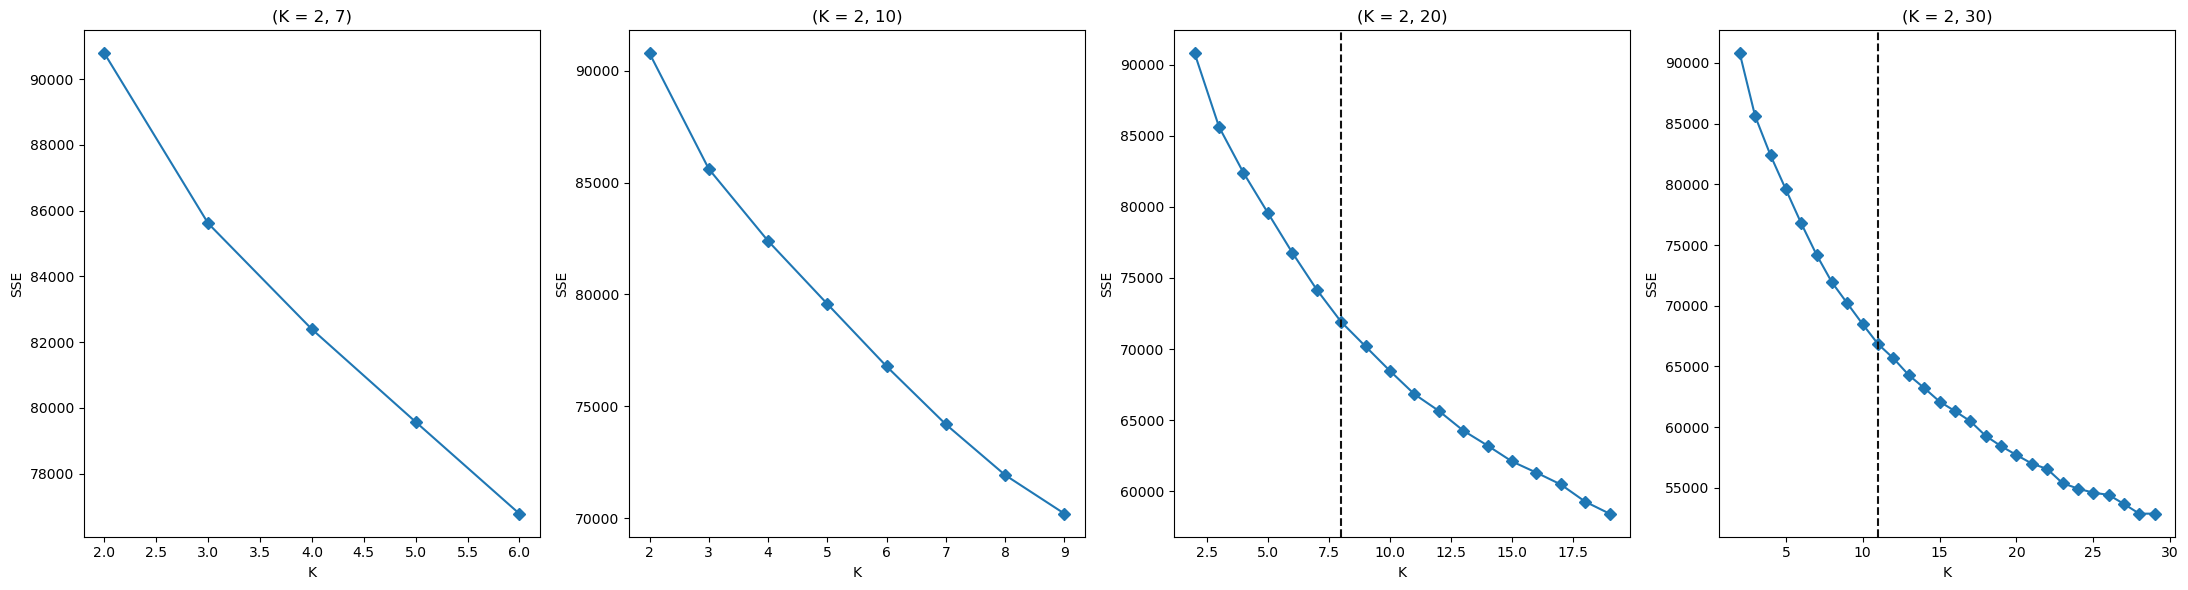

K suggeriti dal metodo elbow: [np.int64(8), np.int64(11)]


In [579]:
from yellowbrick.cluster import KElbowVisualizer
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

random_state = 42  # fisso
# Range multipli da testare (2→10, 2→20, 2→30)
k_start = 2
k_max_list = [7,10, 20, 30]

model = KMeans(n_init=10, max_iter=500, random_state=random_state)

fig, axs = plt.subplots(1, len(k_max_list), figsize=(22, 6))

best_Ks = []

for i, k_max in enumerate(k_max_list):
    
    visualizer = KElbowVisualizer(
        model,
        k=(k_start, k_max),
        metric='distortion',    # SSE (inertia)
        timings=False,
        ax=axs[i]
    )

    visualizer.fit(X)  
    
    axs[i].set_title(f'(K = {k_start}, {k_max})')
    axs[i].set_ylabel('SSE')
    axs[i].set_xlabel('K')
    
    elbow_k = visualizer.elbow_value_
    elbow_score = visualizer.elbow_score_

    if elbow_k is not None and elbow_k not in best_Ks:
        best_Ks.append(elbow_k)

plt.tight_layout()
plt.show()
plt.style.use("default") 


print("K suggeriti dal metodo elbow:", best_Ks)


In [580]:
#ciclo di valutazione delle metriche per k da 2 a 10
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn import metrics

results = []

# Valuta k da 2 a 11
for k in range(2, 20):
    kmeans = KMeans(n_clusters=k, n_init=10, max_iter=500, random_state=random_state)
    kmeans.fit(X)
    labels = kmeans.labels_
    
    sse = kmeans.inertia_
    silhouette = silhouette_score(X, labels)
    db = metrics.davies_bouldin_score(X, labels)
    
    results.append([k, sse, silhouette, db])

results_df = pd.DataFrame(results, columns=["K", "SSE", "Silhouette", "DB_score"])
print(results_df)


     K           SSE  Silhouette  DB_score
0    2  90783.386168    0.255546  2.289246
1    3  85611.496706    0.101324  2.672333
2    4  82391.111896    0.073993  2.798494
3    5  79572.874240    0.064545  2.546730
4    6  76779.694718    0.063178  2.468876
5    7  74185.847280    0.067972  2.322464
6    8  71919.472395    0.072718  2.138908
7    9  70193.196688    0.066818  2.125336
8   10  68474.216787    0.071132  2.087669
9   11  66839.932710    0.070466  2.015742
10  12  65666.032284    0.066075  2.054113
11  13  64282.445911    0.069270  2.021198
12  14  63224.336395    0.074177  2.033533
13  15  62109.377413    0.072991  2.014918
14  16  61323.637611    0.076527  2.032906
15  17  60491.594769    0.072991  2.075992
16  18  59282.895249    0.077735  2.003384
17  19  58437.399822    0.075246  1.918039


Guardando le metriche, k = 2 è la scelta più convincente: la silhouette è nettamente più alta (≈0.26) rispetto a tutti gli altri valori di k, che crollano intorno a 0.06–0.10. Questo indica che i dati non sembrano formare molti gruppi ben separati, ma piuttosto un continuum: oltre k=2 si “spezzano” ulteriormente i pazienti senza creare cluster realmente distinti.


/var/folders/6c/ryq330rs7bl7nmdhthbq78380000gn/T/ipykernel_16376/2100201248.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=unique_values, y=value_counts, palette="tab10")


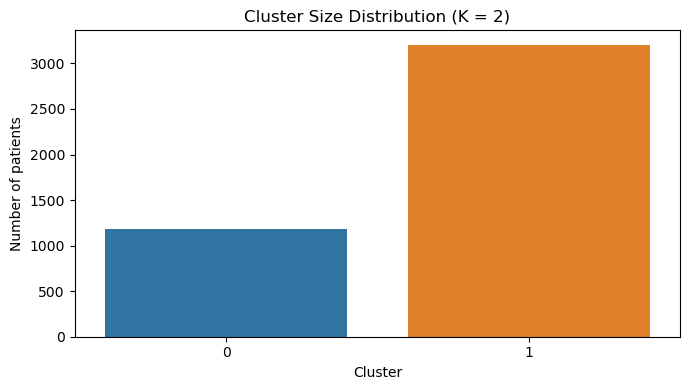

Cluster 0: 1181 pazienti
Cluster 1: 3203 pazienti


In [581]:
from sklearn.cluster import KMeans

k = 2
kmeans = KMeans(n_clusters=k, n_init=10, max_iter=500, random_state=random_state)
kmeans.fit(X)

labels = kmeans.labels_

np.unique(labels, return_counts=True)

# Distribuzione dei pazienti nei cluster
unique_values, value_counts = np.unique(labels, return_counts=True)

plt.figure(figsize=(7, 4))
sns.barplot(x=unique_values, y=value_counts, palette="tab10")

plt.xlabel("Cluster")
plt.ylabel("Number of patients")
plt.title("Cluster Size Distribution (K = 2)")
plt.tight_layout()
plt.show()

# Stampa numeri
for c, n in zip(unique_values, value_counts):
    print(f"Cluster {c}: {n} pazienti")



In [582]:
#centroids
centroids_scaled = pd.DataFrame(kmeans.cluster_centers_, columns=numeric_df.columns)
centroids_scaled.index.name = "cluster"
display(centroids_scaled)

,number_of_hadm,age,lab_event_count,microbio_test_count,unique_microorganisms_count,unique_procedures_count,max_glucose,max_potassium,max_sodium,max_creatinine,...,max_ntprobnp,max_ptt,max_inr(pt),max_hemoglobin,max_platelet count,max_white blood cells,max_cholesterol ratio (total/hdl),max_ph,max_pco2,abnormal_lab_event_ratio
cluster,,,,,,,,,,,,,,,,,,,,,
0,0.446017,0.159267,0.994433,0.880491,0.595323,0.459779,0.784133,0.819801,0.316133,0.708283,...,0.290530,0.532216,0.558391,-0.280929,0.406462,0.568627,-0.050974,0.724767,0.772922,0.843462
1,-0.164454,-0.058724,-0.366664,-0.324652,-0.219506,-0.169528,-0.289123,-0.302275,-0.116564,-0.261156,...,-0.107123,-0.196237,-0.205888,0.103583,-0.149869,-0.209662,0.018795,-0.267234,-0.284989,-0.310999


Questi numeri sono z-score: 0 è la media del dataset, positivo = sopra media, negativo = sotto media.

Il **Cluster 0** mostra un profilo chiaramente più “intenso/complesso”: più ricoveri (`number_of_hadm`), molti più esami di laboratorio e microbiologia (`lab_event_count`, `microbio_test_count`), più procedure, e valori massimi più alti su diversi marker (es. `max_glucose`, `max_creatinine`, `max_pco2`). Spicca anche un `abnormal_lab_event_ratio` nettamente sopra la media, segnale di maggiore quota di risultati anomali. In controtendenza, `max_hemoglobin` è sotto media.

Il **Cluster 1** è l’opposto: conteggi e massimi generalmente **sotto la media** e un `abnormal_lab_event_ratio` più basso, quindi un profilo più “standard/stabile” rispetto al Cluster 0.


In [583]:
#attach labels to original profile dataframe
assert len(labels) == len(profile_df) == len(numeric_df)

dfc = profile_df.copy()
dfc["cluster"] = labels


In [584]:
#means and medians of clusters
means = dfc.groupby("cluster")[numeric_df.columns].mean()
medians = dfc.groupby("cluster")[numeric_df.columns].median()
print("Cluster Means:")
display(means)
print("Cluster Medians:")
display(medians)


Cluster Means:


,number_of_hadm,age,lab_event_count,microbio_test_count,unique_microorganisms_count,unique_procedures_count,max_glucose,max_potassium,max_sodium,max_creatinine,...,max_ntprobnp,max_ptt,max_inr(pt),max_hemoglobin,max_platelet count,max_white blood cells,max_cholesterol ratio (total/hdl),max_ph,max_pco2,abnormal_lab_event_ratio
cluster,,,,,,,,,,,,,,,,,,,,,
0,1.274344,71.597798,323.744285,2.641829,0.555461,4.686706,5.327600,1.033944,0.733700,3.426515,...,7.211450,4.977435,6.929297,-0.296112,0.536948,1.549498,0.184952,0.550127,1.029213,0.496534
1,1.045582,69.540743,84.913831,0.680300,0.070559,2.652513,2.313828,0.613272,0.602092,1.159270,...,1.095664,2.371506,2.403606,-0.113043,0.325059,0.728973,0.217974,0.066344,0.083921,0.320780


Cluster Medians:


,number_of_hadm,age,lab_event_count,microbio_test_count,unique_microorganisms_count,unique_procedures_count,max_glucose,max_potassium,max_sodium,max_creatinine,...,max_ntprobnp,max_ptt,max_inr(pt),max_hemoglobin,max_platelet count,max_white blood cells,max_cholesterol ratio (total/hdl),max_ph,max_pco2,abnormal_lab_event_ratio
cluster,,,,,,,,,,,,,,,,,,,,,
0,1.0,71.0,259.0,2.0,0.0,4.0,4.257143,0.944444,0.750000,2.142857,...,0.0,4.153846,3.0,-0.30,0.448000,1.285714,0.0,0.3,0.6,0.494737
1,1.0,69.0,72.0,0.0,0.0,2.0,1.800000,0.611111,0.666667,0.857143,...,0.0,0.826087,1.0,-0.05,0.275862,0.633333,0.0,0.0,0.0,0.330357


In scala reale la differenza tra i cluster è molto netta e sembra descrivere soprattutto un asse di intensità/complessità clinica.

- **Cluster 0 (più intenso)**: molti più esami di laboratorio, più procedure e più attività microbiologica . Anche l’abnormal_lab_event_ratio è più alto, coerente con un profilo più “alterato”. In media compaiono anche massimi più elevati (es. glucosio e creatinina).
- **Cluster 1 (più standard)**: profilo opposto, con conteggi molto più bassi e ratio di anomalia più contenuto. Le mediane a 0 per microbiologia indicano che molti pazienti di questo gruppo non hanno test microbiologici registrati.

L’età e il numero di ricoveri cambiano poco (mediane simili), quindi la separazione non è “anagrafica”, ma legata soprattutto a quanto e quanto spesso i pazienti vengono testati/procedurati e a quante anomalie emergono.


In [585]:
#Top features” that distinguish each cluster
z = centroids_scaled.copy()

for c in z.index:
    top_pos = z.loc[c].sort_values(ascending=False).head(8)
    top_neg = z.loc[c].sort_values(ascending=True).head(8)
    print(f"\n=== Cluster {c} (n={np.sum(labels==c)}) ===")
    print("==Più alti della media:==")
    print(top_pos)
    print("==Più bassi della media:==")
    print(top_neg)



=== Cluster 0 (n=1181) ===
==Più alti della media:==
lab_event_count             0.994433
max_urea nitrogen           0.936110
microbio_test_count         0.880491
abnormal_lab_event_ratio    0.843462
max_potassium               0.819801
max_glucose                 0.784133
max_pco2                    0.772922
max_ph                      0.724767
Name: 0, dtype: float64
==Più bassi della media:==
max_hemoglobin                      -0.280929
max_cholesterol ratio (total/hdl)   -0.050974
age                                  0.159267
max_troponin t                       0.255970
max_ntprobnp                         0.290530
max_sodium                           0.316133
max_calcium, total                   0.344220
max_platelet count                   0.406462
Name: 0, dtype: float64

=== Cluster 1 (n=3203) ===
==Più alti della media:==
max_hemoglobin                       0.103583
max_cholesterol ratio (total/hdl)    0.018795
age                                 -0.058724
max_troponin t 

In [586]:
#spreadness across clusters to identify the most discriminative features
#Le feature in cima allo spread sono quelle su cui i cluster sono più separati (a livello di centroidi).
spread = centroids_scaled.max(axis=0) - centroids_scaled.min(axis=0)
display(spread.sort_values(ascending=False).head(15))


lab_event_count                1.361098
max_urea nitrogen              1.281270
microbio_test_count            1.205143
abnormal_lab_event_ratio       1.154461
max_potassium                  1.122076
max_glucose                    1.073255
max_pco2                       1.057911
max_ph                         0.992001
max_creatinine                 0.969439
unique_microorganisms_count    0.814829
max_bicarbonate                0.800189
max_white blood cells          0.778289
max_inr(pt)                    0.764279
max_ptt                        0.728453
unique_procedures_count        0.629307
dtype: float64

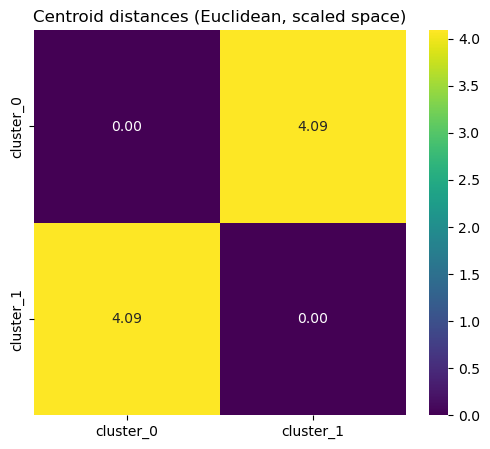

In [587]:

# Centroidi nello spazio in cui KMeans è stato fittato (valori in "z-score space").
centers = pd.DataFrame(
    kmeans.cluster_centers_,
    index=[f"cluster_{i}" for i in range(kmeans.n_clusters)],
    columns=numeric_df.columns
)

C = centers.to_numpy()
dist_matrix = np.linalg.norm(C[:, None, :] - C[None, :, :], axis=2)


plt.figure(figsize=(6, 5))
sns.heatmap(
    dist_matrix,
    annot=True,
    fmt=".2f",
    cmap="viridis",
    xticklabels=centers.index,
    yticklabels=centers.index
)
plt.title("Centroid distances (Euclidean, scaled space)")
plt.show()

# Interpretazione:
# - Ogni cella (i,j) mostra quanto sono distanti i centroidi dei cluster i e j nello spazio standardizzato.
# - Valori più grandi => cluster mediamente più separati (centroidi più lontani).
# - Valori piccoli => cluster simili in media (centroidi vicini).



Coppie manuali usate: [('age', 'lab_event_count'), ('age', 'microbio_test_count'), ('lab_event_count', 'unique_procedures_count'), ('max_glucose', 'abnormal_lab_event_ratio')]


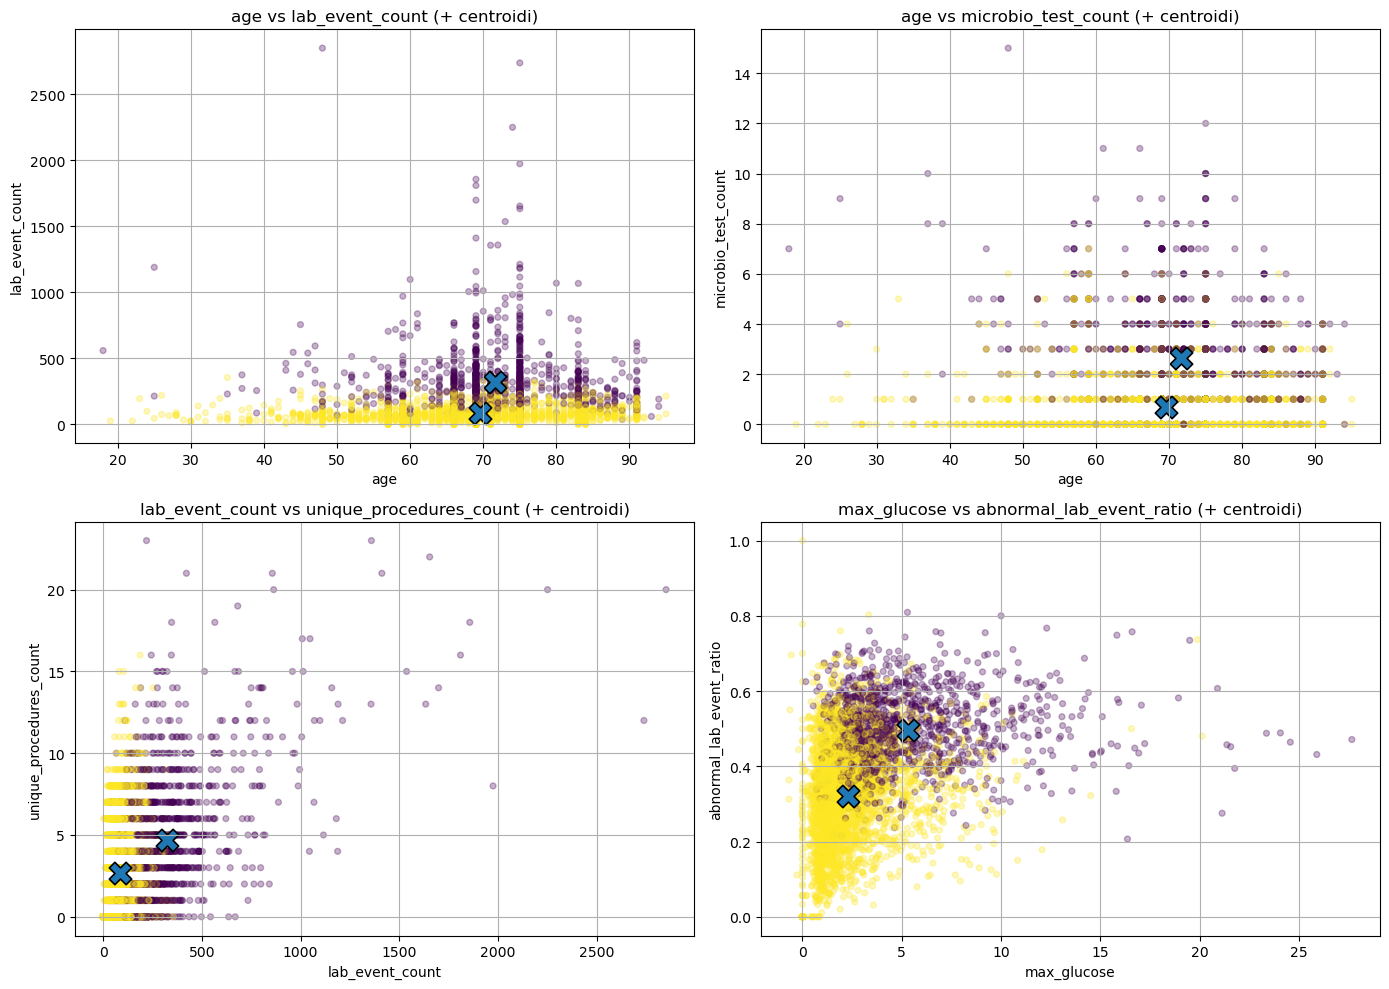

Coppie extra usate: [('max_creatinine', 'max_urea nitrogen'), ('max_creatinine', 'max_potassium'), ('max_inr(pt)', 'max_ptt'), ('max_inr(pt)', 'max_platelet count')]


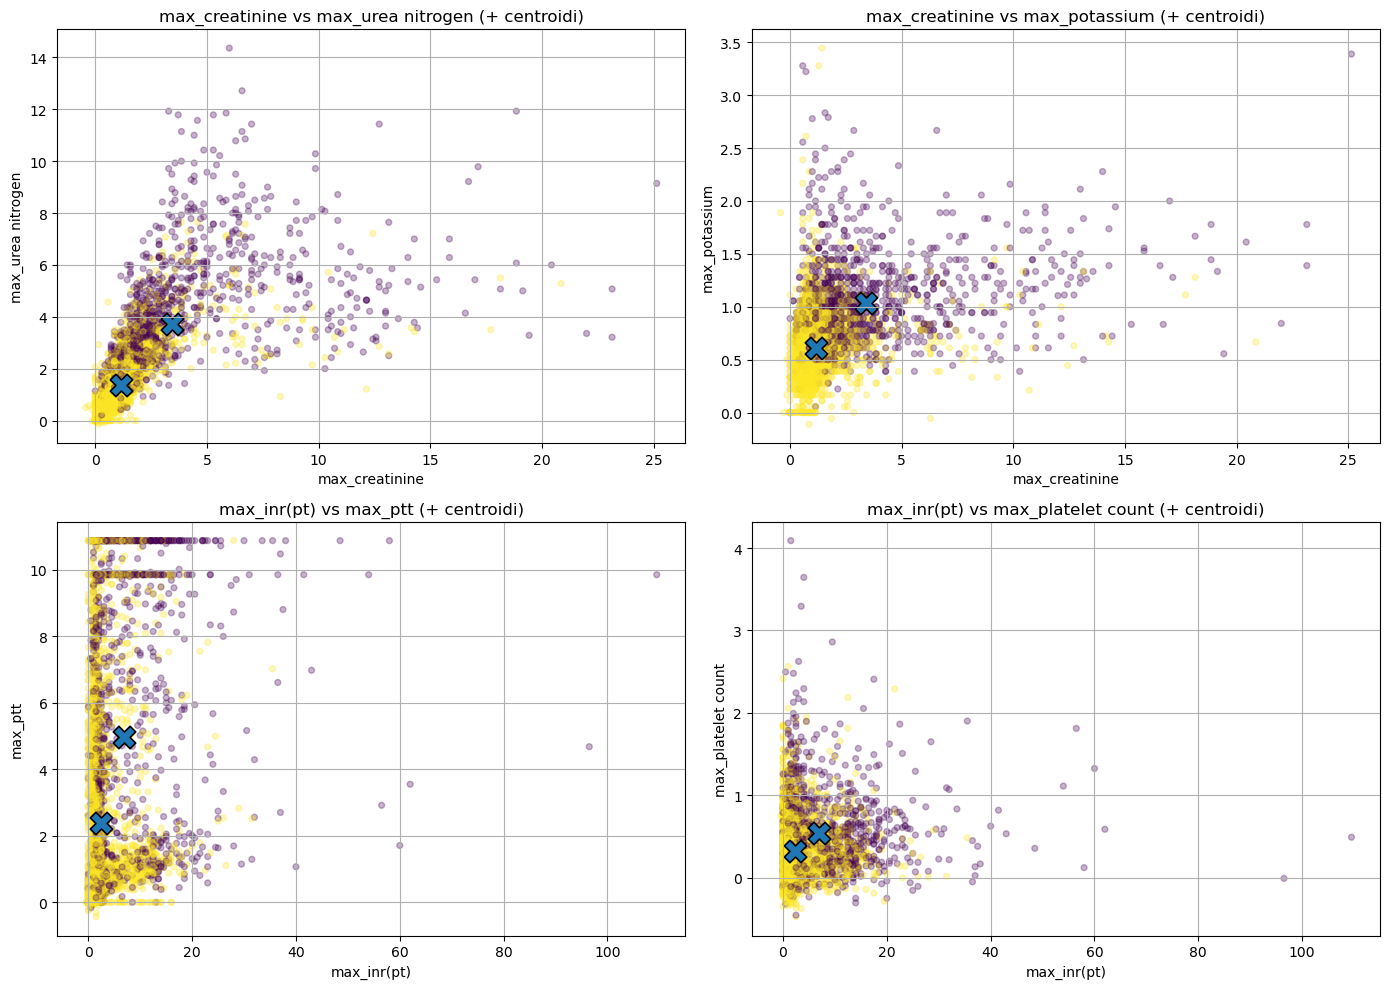

In [588]:
import numpy as np
import matplotlib.pyplot as plt

def scatter_with_centroids(ax, xcol, ycol, df, labels, kmeans, scaler, numeric_cols,
                           s=20, alpha=0.35, centroid_size=260):
    """
    Scatter in scala originale (df) colorato con labels (KMeans su X scalato),
    e centroidi riportati in scala originale usando scaler.
    NOTA: numeric_cols è mantenuto solo per compatibilità, ma l'indicizzazione
    ora avviene in modo robusto usando df.columns (stesso ordine usato per X).
    """

    # Indici delle feature nell'ordine effettivo usato per costruire X
    xi = df.columns.get_loc(xcol)
    yi = df.columns.get_loc(ycol)

    x = df[xcol].values
    y = df[ycol].values

    # Centroidi in spazio scalato (z-score) -> riportati in scala originale
    cent = kmeans.cluster_centers_
    cx = cent[:, xi] * scaler.scale_[xi] + scaler.mean_[xi]
    cy = cent[:, yi] * scaler.scale_[yi] + scaler.mean_[yi]

    sc = ax.scatter(x, y, c=labels, s=s, alpha=alpha)
    ax.scatter(cx, cy, marker="X", s=centroid_size, edgecolor="black", linewidth=1.2)

    ax.set_xlabel(xcol)
    ax.set_ylabel(ycol)
    ax.grid(True)
    return sc

pairs = [
    ("age", "lab_event_count"),
    ("age", "microbio_test_count"),
    ("lab_event_count", "unique_procedures_count"),
    ("max_glucose", "abnormal_lab_event_ratio"),
]

pairs = [(a, b) for a, b in pairs if a in numeric_df.columns and b in numeric_df.columns]
print("Coppie manuali usate:", pairs)

n = len(pairs)
cols = 2
rows = int(np.ceil(n / cols))

fig, axs = plt.subplots(rows, cols, figsize=(14, 5 * rows))
axs = np.array(axs).reshape(-1)

for idx, (xcol, ycol) in enumerate(pairs):
    scatter_with_centroids(
        axs[idx], xcol, ycol,
        df=numeric_df, labels=labels,
        kmeans=kmeans, scaler=scaler, numeric_cols=numeric_cols,
        s=18, alpha=0.30, centroid_size=260
    )
    axs[idx].set_title(f"{xcol} vs {ycol} (+ centroidi)")

for j in range(idx + 1, len(axs)):
    axs[j].axis("off")

plt.tight_layout()
plt.show()

pairs_extra = [
    ("max_creatinine", "max_urea nitrogen"),
    ("max_creatinine", "max_potassium"),
    ("max_inr(pt)", "max_ptt"),
    ("max_inr(pt)", "max_platelet count"),
]

pairs_extra = [(a, b) for a, b in pairs_extra if a in numeric_df.columns and b in numeric_df.columns]
print("Coppie extra usate:", pairs_extra)

n = len(pairs_extra)
cols = 2
rows = int(np.ceil(n / cols))

fig, axs = plt.subplots(rows, cols, figsize=(14, 5 * rows))
axs = np.array(axs).reshape(-1)

for idx, (xcol, ycol) in enumerate(pairs_extra):
    scatter_with_centroids(
        axs[idx], xcol, ycol,
        df=numeric_df, labels=labels,
        kmeans=kmeans, scaler=scaler, numeric_cols=numeric_cols,
        s=18, alpha=0.30, centroid_size=260
    )
    axs[idx].set_title(f"{xcol} vs {ycol} (+ centroidi)")

for j in range(idx + 1, len(axs)):
    axs[j].axis("off")

plt.tight_layout()
plt.show()


Triple manuali usate: [('age', 'lab_event_count', 'microbio_test_count'), ('lab_event_count', 'unique_procedures_count', 'abnormal_lab_event_ratio'), ('max_glucose', 'abnormal_lab_event_ratio', 'lab_event_count')]


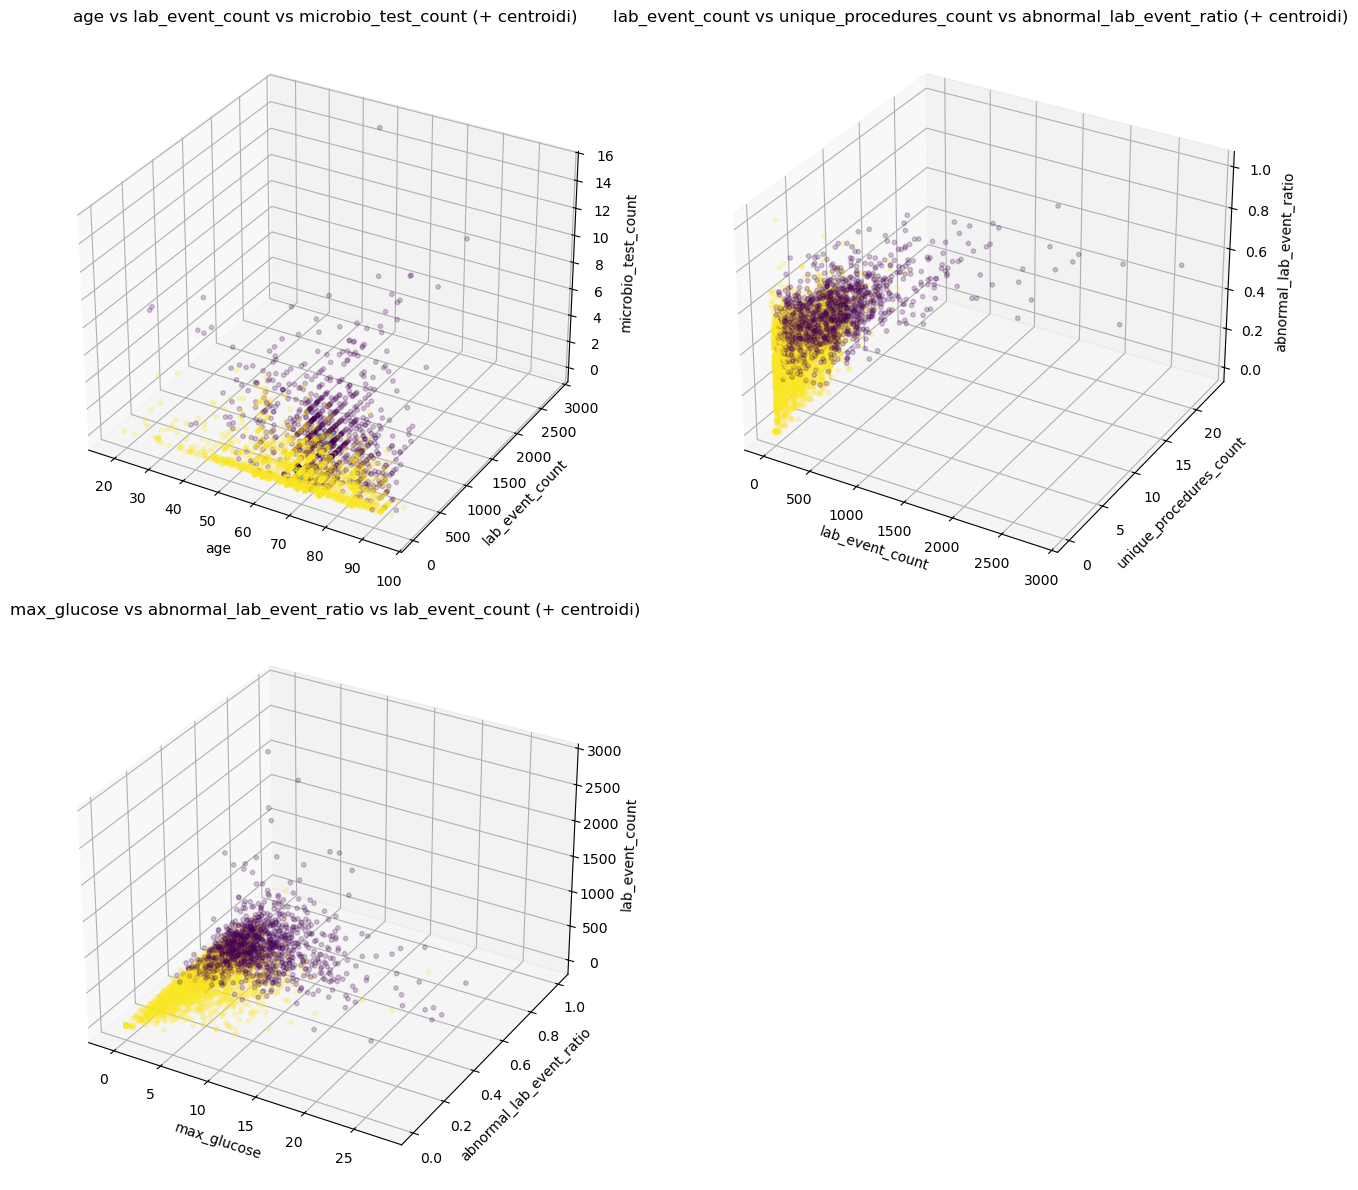

Triple extra usate: [('max_creatinine', 'max_urea nitrogen', 'max_potassium'), ('max_inr(pt)', 'max_ptt', 'max_platelet count'), ('max_creatinine', 'max_potassium', 'abnormal_lab_event_ratio')]


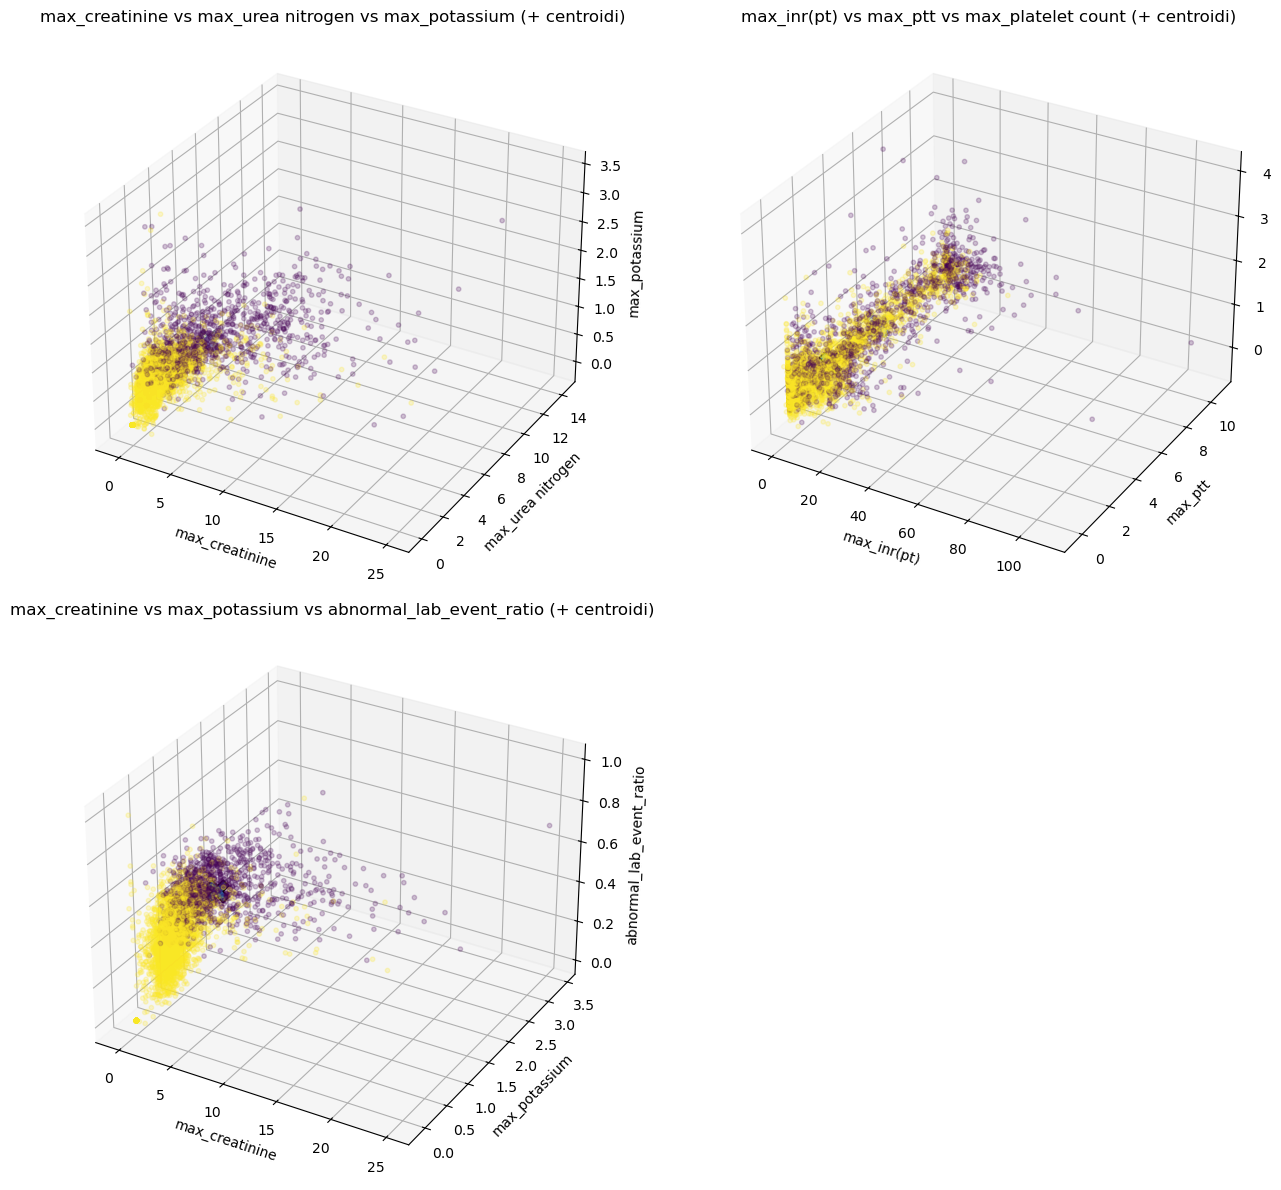

In [589]:

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (necessario per proiezione 3D)

def scatter3d_with_centroids(ax, xcol, ycol, zcol, df, labels, kmeans, scaler,
                             s=12, alpha=0.25, centroid_size=260):
    """
    Scatter 3D in scala originale (df) colorato con labels (KMeans su X scalato),
    con centroidi riportati in scala originale via scaler.
    """
    # indici feature nell'ordine effettivo (df.columns == ordine usato per X)
    xi = df.columns.get_loc(xcol)
    yi = df.columns.get_loc(ycol)
    zi = df.columns.get_loc(zcol)

    x = df[xcol].values
    y = df[ycol].values
    z = df[zcol].values

    cent = kmeans.cluster_centers_
    cx = cent[:, xi] * scaler.scale_[xi] + scaler.mean_[xi]
    cy = cent[:, yi] * scaler.scale_[yi] + scaler.mean_[yi]
    cz = cent[:, zi] * scaler.scale_[zi] + scaler.mean_[zi]

    ax.scatter(x, y, z, c=labels, s=s, alpha=alpha)
    ax.scatter(cx, cy, cz, marker="X", s=centroid_size, edgecolor="black", linewidth=1.2)

    ax.set_xlabel(xcol)
    ax.set_ylabel(ycol)
    ax.set_zlabel(zcol)
    ax.set_title(f"{xcol} vs {ycol} vs {zcol} (+ centroidi)")
    ax.grid(True)


# --- triple "manuali" (derivate dalle tue coppie) ---
triples = [
    ("age", "lab_event_count", "microbio_test_count"),
    ("lab_event_count", "unique_procedures_count", "abnormal_lab_event_ratio"),
    ("max_glucose", "abnormal_lab_event_ratio", "lab_event_count"),
]

# tieni solo triple valide
triples = [(a, b, c) for a, b, c in triples
           if a in numeric_df.columns and b in numeric_df.columns and c in numeric_df.columns]
print("Triple manuali usate:", triples)

n = len(triples)
cols = 2
rows = int(np.ceil(n / cols))

fig = plt.figure(figsize=(14, 6 * rows))
for i, (xcol, ycol, zcol) in enumerate(triples, start=1):
    ax = fig.add_subplot(rows, cols, i, projection="3d")
    scatter3d_with_centroids(
        ax, xcol, ycol, zcol,
        df=numeric_df, labels=labels, kmeans=kmeans, scaler=scaler,
        s=10, alpha=0.22, centroid_size=260
    )

# spegni eventuali subplot vuoti
for j in range(n + 1, rows * cols + 1):
    ax = fig.add_subplot(rows, cols, j, projection="3d")
    ax.set_axis_off()

plt.tight_layout()
plt.show()


# --- triple "extra" (derivate dalle tue coppie extra) ---
triples_extra = [
    ("max_creatinine", "max_urea nitrogen", "max_potassium"),
    ("max_inr(pt)", "max_ptt", "max_platelet count"),
    ("max_creatinine", "max_potassium", "abnormal_lab_event_ratio"),
]

triples_extra = [(a, b, c) for a, b, c in triples_extra
                 if a in numeric_df.columns and b in numeric_df.columns and c in numeric_df.columns]
print("Triple extra usate:", triples_extra)

n = len(triples_extra)
cols = 2
rows = int(np.ceil(n / cols))

fig = plt.figure(figsize=(14, 6 * rows))
for i, (xcol, ycol, zcol) in enumerate(triples_extra, start=1):
    ax = fig.add_subplot(rows, cols, i, projection="3d")
    scatter3d_with_centroids(
        ax, xcol, ycol, zcol,
        df=numeric_df, labels=labels, kmeans=kmeans, scaler=scaler,
        s=10, alpha=0.22, centroid_size=260
    )

for j in range(n + 1, rows * cols + 1):
    ax = fig.add_subplot(rows, cols, j, projection="3d")
    ax.set_axis_off()

plt.tight_layout()
plt.show()


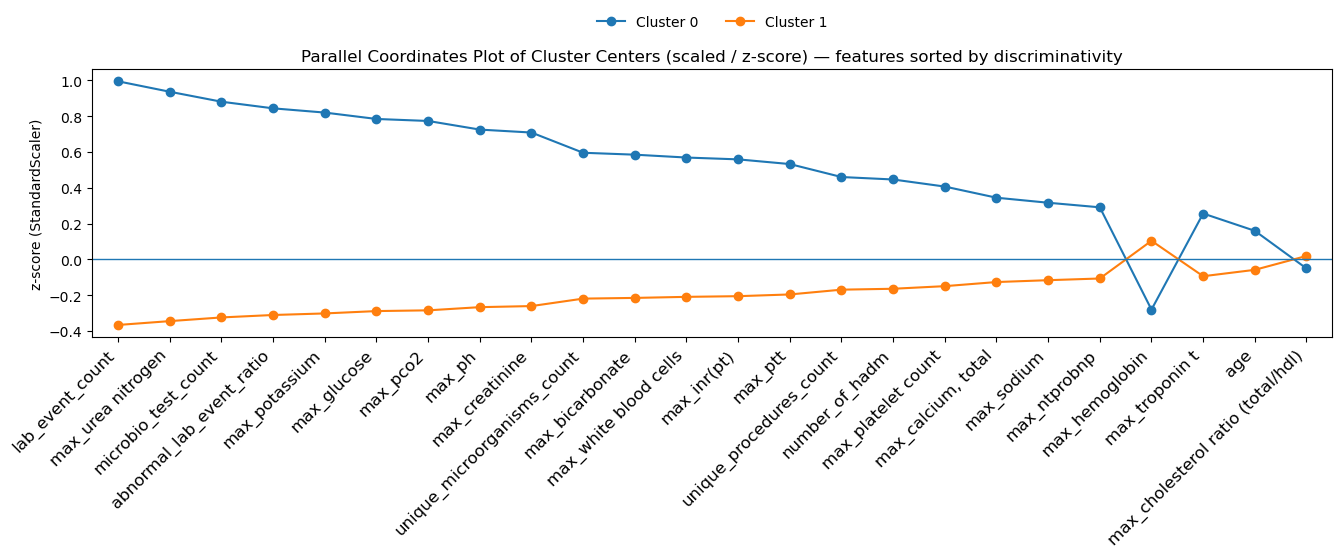

In [590]:
# Parallel Coordinates (centroidi in z-score) con feature ordinate per discriminatività

centers_scaled = kmeans.cluster_centers_   # (k, p) nello spazio scalato
cols = list(numeric_df.columns)

# discriminatività = (max - min) tra centroidi per feature (in z-score)
spread = centers_scaled.max(axis=0) - centers_scaled.min(axis=0)
order = np.argsort(-spread)  # descending

centers_ord = centers_scaled[:, order]
cols_ord = [cols[i] for i in order]

N = centers_ord.shape[1]
x = np.arange(N)

plt.figure(figsize=(16, 4))
for i in range(centers_ord.shape[0]):
    plt.plot(x, centers_ord[i], marker='o', label=f'Cluster {i}')

plt.axhline(0, linewidth=1)  # baseline: media globale
plt.xticks(x, cols_ord, fontsize=12, rotation=45, ha='right')
plt.xlim(-0.5, N - 0.5)
plt.ylabel("z-score (StandardScaler)")

plt.legend(loc='upper center', bbox_to_anchor=(0.5, 1.25),
           ncol=centers_ord.shape[0], frameon=False)

plt.subplots_adjust(top=0.78)
plt.title("Parallel Coordinates Plot of Cluster Centers (scaled / z-score) — features sorted by discriminativity")
plt.show()


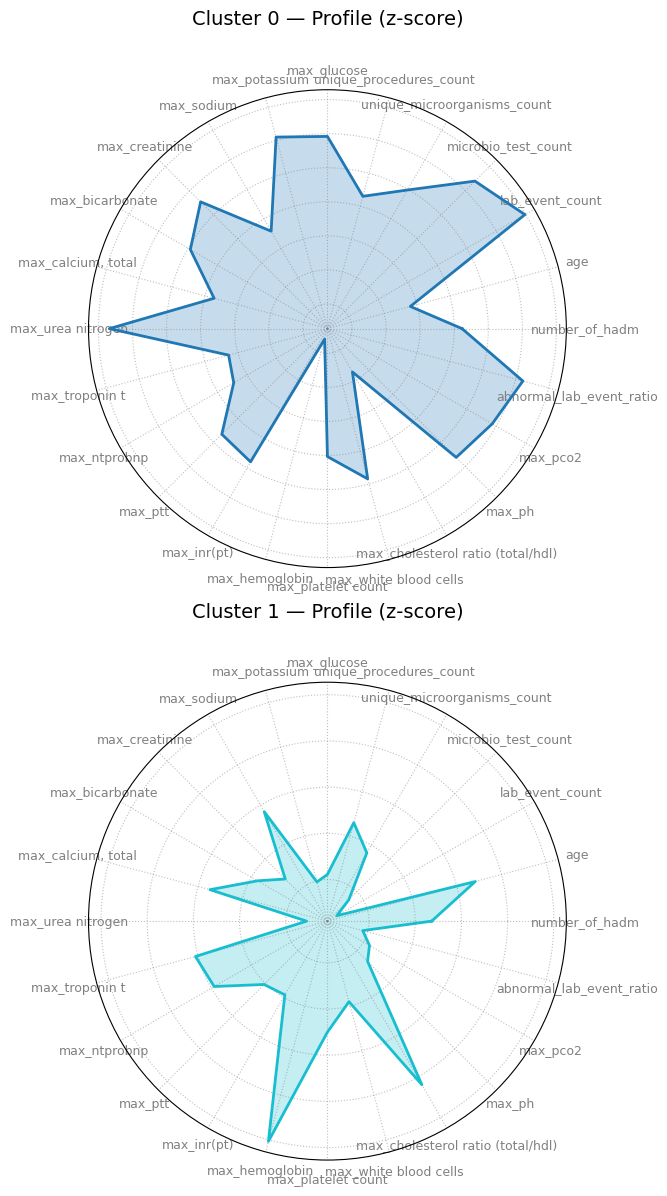

In [591]:
from math import pi
import numpy as np
import matplotlib.pyplot as plt

centers_np = kmeans.cluster_centers_  # <-- SCALATI (z-score)

N = centers_np.shape[1]
features_labels = numeric_df.columns.tolist()
colors = plt.cm.tab10(np.linspace(0, 1, centers_np.shape[0]))

plt.figure(figsize=(12, 12))

for cluster_id in range(centers_np.shape[0]):
    values = centers_np[cluster_id].tolist()
    values += values[:1]

    angles = [n / float(N) * 2*pi for n in range(N)]
    angles += angles[:1]

    ax = plt.subplot(centers_np.shape[0], 1, cluster_id + 1, polar=True)

    ax.plot(angles, values, linewidth=2, color=colors[cluster_id])
    ax.fill(angles, values, alpha=0.25, color=colors[cluster_id])

    plt.xticks(angles[:-1], features_labels, size=9, color="grey")
    ax.grid(color="grey", linestyle="dotted", alpha=0.5)
    ax.set_yticklabels([])
    ax.set_title(f"Cluster {cluster_id} — Profile (z-score)", size=14, y=1.12)

plt.tight_layout()
plt.show()


/var/folders/6c/ryq330rs7bl7nmdhthbq78380000gn/T/ipykernel_16376/2495088612.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Cluster", y=var, data=df_box, palette="tab10")
/var/folders/6c/ryq330rs7bl7nmdhthbq78380000gn/T/ipykernel_16376/2495088612.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Cluster", y=var, data=df_box, palette="tab10")
/var/folders/6c/ryq330rs7bl7nmdhthbq78380000gn/T/ipykernel_16376/2495088612.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Cluster", y=var, data=df_box, palette="tab10")


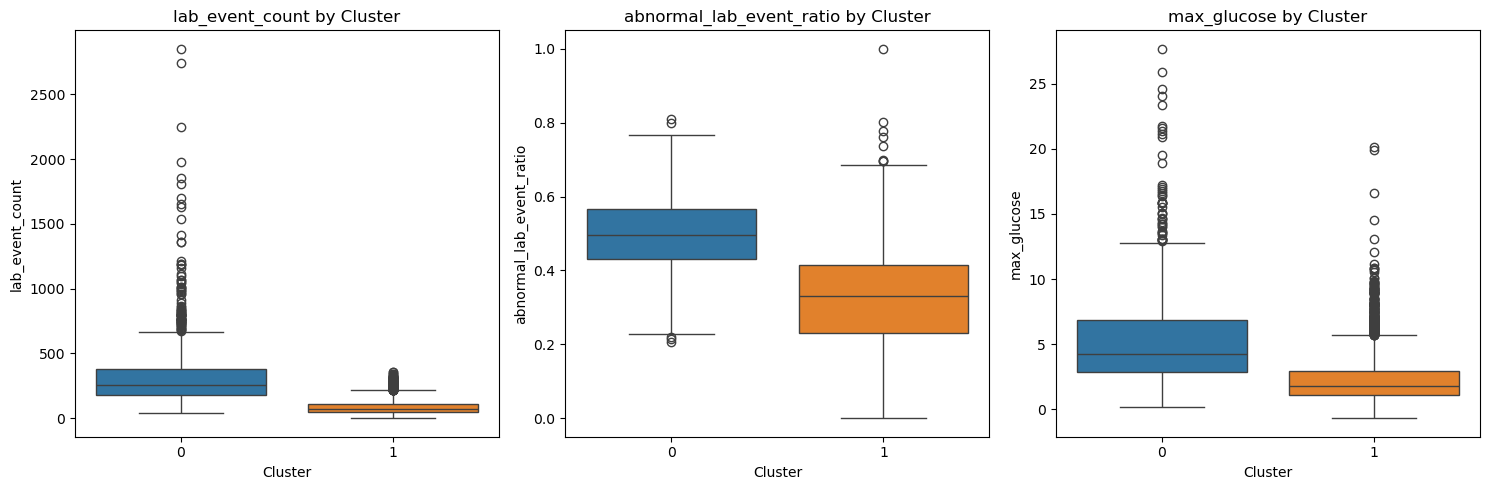

In [592]:
import seaborn as sns
import matplotlib.pyplot as plt

# Creiamo un DataFrame con i dati originali e il cluster assegnato
df_box = numeric_df.copy()
df_box["Cluster"] = labels

vars_to_plot = [
    "lab_event_count",
    "abnormal_lab_event_ratio",
    "max_glucose",
]

plt.figure(figsize=(15, 5))

for i, var in enumerate(vars_to_plot, 1):
    plt.subplot(1, len(vars_to_plot), i)
    sns.boxplot(x="Cluster", y=var, data=df_box, palette="tab10")
    plt.title(f"{var} by Cluster")
    plt.xlabel("Cluster")
    plt.ylabel(var)

plt.tight_layout()
plt.show()


I boxplot confermano con grande chiarezza la separazione tra i tre cluster individuati da K-Means. Per tutte e tre le variabili cliniche considerate, lab_event_count, abnormal_lab_event_ratio e max_glucose, emerge una struttura ordinata e coerente:

- **Cluster 0** presenta valori bassi in tutte le variabili, indicando pazienti con un profilo clinico semplice e un numero molto ridotto di esami eseguiti.

- **Cluster 1** mostra valori intermedi, con un’attività diagnostica maggiore e un livello di anomalie superiore rispetto al cluster precedente.

- **Cluster 2** evidenzia le mediane e i massimi più elevati, configurandosi come il gruppo di pazienti più complesso e clinicamente instabile, caratterizzato da un numero elevato di esami, molte anomalie di laboratorio e valori glicemici più alti.


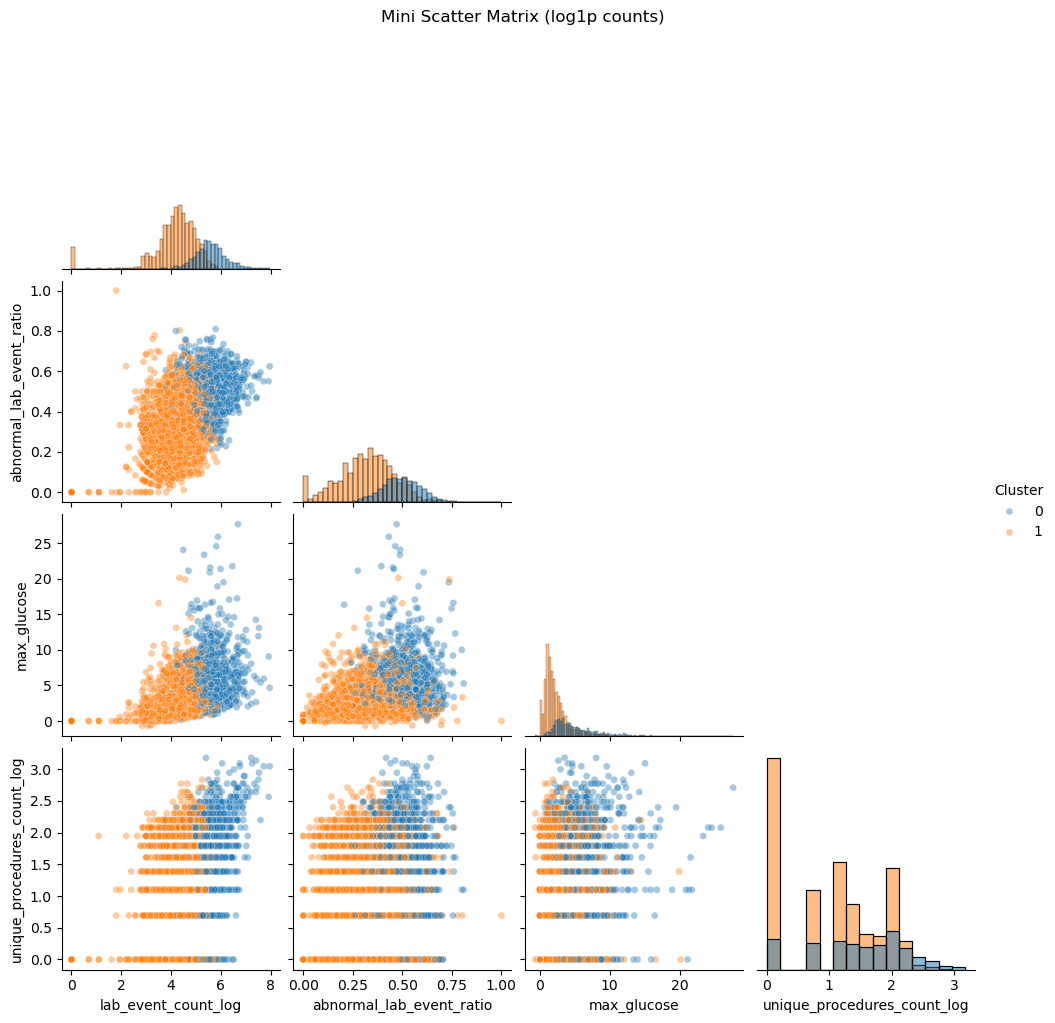

In [593]:
df_scatter = numeric_df.copy()
df_scatter["Cluster"] = labels

df_scatter["lab_event_count_log"] = np.log1p(df_scatter["lab_event_count"])
df_scatter["unique_procedures_count_log"] = np.log1p(df_scatter["unique_procedures_count"])

vars_scatter = [
    "lab_event_count_log",
    "abnormal_lab_event_ratio",
    "max_glucose",
    "unique_procedures_count_log"
]

sns.pairplot(
    df_scatter[vars_scatter + ["Cluster"]],
    hue="Cluster",
    palette="tab10",
    corner=True,
    diag_kind="hist",
    plot_kws={"alpha": 0.4, "s": 25}
)

plt.suptitle("Mini Scatter Matrix (log1p counts)", y=1.02)
plt.show()
